<a href="https://colab.research.google.com/github/prakharsrivcodes/DEEP-LEARNING-PRACTICE/blob/main/MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
from torchvision import datasets, transforms
from torch import nn
from torch.nn import Sequential, Linear, Flatten

# Load MNIST dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.79MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 160kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.2MB/s]


In [3]:
len(train_dataset), len(test_dataset)

(60000, 10000)

In [4]:
image, label = train_dataset[0]
image.shape

torch.Size([1, 28, 28])

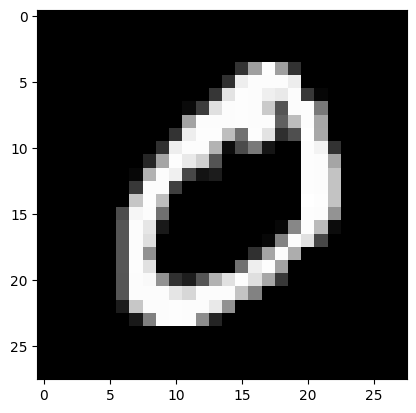

In [5]:
import matplotlib.pyplot as plt

plt.imshow(train_dataset.data[1], cmap='gray')
plt.show()

In [6]:
X_train = train_dataset.data.float() / 255
X_test = test_dataset.data.float() / 255

In [7]:
import torch.nn as nn

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

In [8]:
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


In [9]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

In [10]:
from torch.utils.data import TensorDataset, DataLoader, random_split

train_dataset = TensorDataset(X_train, train_dataset.targets)

In [11]:
model.eval()

with torch.no_grad():
    y_prob = model(X_test)

In [12]:
y_pred = y_prob.argmax(dim=1)

In [14]:
y_test = test_dataset.targets.numpy()

accuracy_score(y_test, y_pred.cpu().numpy())

0.1029